# Домашнее задание 3.1. Аттрактор Лоренца

**Уровень:** 🟢  
**Выполнил:** Константин Мурусидзе, 6 курс мехмата МГУ

Рассчитывается движение системы Лоренца при $\rho=28$.
Исследуется рост расстояния между двумя решениями с близкими начальными условиями
и проверяется влияние точности интегрирования.

## 1. Уравнения и метод

$$
\dot x=\sigma(y-x),\qquad
\dot y=x(\rho-z)-y,\qquad
\dot z=xy-\beta z,
$$

где $\sigma=10$, $\beta=8/3$, $\rho=28$.
Начальные условия: $(x,y,z)=(1,1,1)$.

Для интегрирования используется метод Рунге—Кутты DOP853 из
[`scipy.integrate.solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).
Метод адаптивно выбирает шаг. `rtol` и `atol` задают относительный и абсолютный
допуски локальной ошибки, а `max_step` ограничивает шаг сверху.
Сетка `t_eval` задаёт только моменты вывода результата.

Первые $30$ единиц времени отводятся переходному процессу.
Из состояния в момент $t=30$ запускаются две траектории на интервале $0\le\tau\le40$,
где $\tau$ — время от повторного запуска.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25})

sigma = 10.0
beta = 8/3
rho = 28.0
delta0 = 1e-6


def lorenz(_t, state):
    x, y, z = state
    return [sigma*(y - x), x*(rho - z) - y, x*y - beta*z]


def integrate(initial, time, settings):
    result = solve_ivp(
        lorenz, (time[0], time[-1]), initial,
        method="DOP853", t_eval=time, **settings
    )
    if not result.success:
        raise RuntimeError(result.message)
    return result.y.T


settings_basic = dict(rtol=1e-11, atol=1e-13, max_step=0.05)
settings_fine = dict(rtol=1e-12, atol=1e-14, max_step=0.025)

t_transient = 30.0
time_warmup = np.linspace(0.0, t_transient, 3001)
warmup = integrate([1.0, 1.0, 1.0], time_warmup, settings_fine)
start = warmup[-1].copy()
start_perturbed = start + np.array([delta0, 0.0, 0.0])

time = np.linspace(0.0, 40.0, 8001)
base_basic = integrate(start, time, settings_basic)
pair_basic = integrate(start_perturbed, time, settings_basic)
base_fine = integrate(start, time, settings_fine)
pair_fine = integrate(start_perturbed, time, settings_fine)

print("Начальная точка после переходного процесса:", start)
print("Начальное расстояние:", np.linalg.norm(start_perturbed - start))
print("Основной расчёт:", settings_basic)
print("Уточнённый расчёт:", settings_fine)


Начальная точка после переходного процесса: [ 7.39312349  2.04968245 31.75950399]
Начальное расстояние: 1.000000000139778e-06
Основной расчёт: {'rtol': 1e-11, 'atol': 1e-13, 'max_step': 0.05}
Уточнённый расчёт: {'rtol': 1e-12, 'atol': 1e-14, 'max_step': 0.025}


## 2. Временные ряды и фазовые проекции

Временные ряды показаны от исходного состояния $(1,1,1)$.
После $t=30$ продолжается уточнённая невозмущённая траектория.
Фазовые проекции строятся только после переходного процесса.

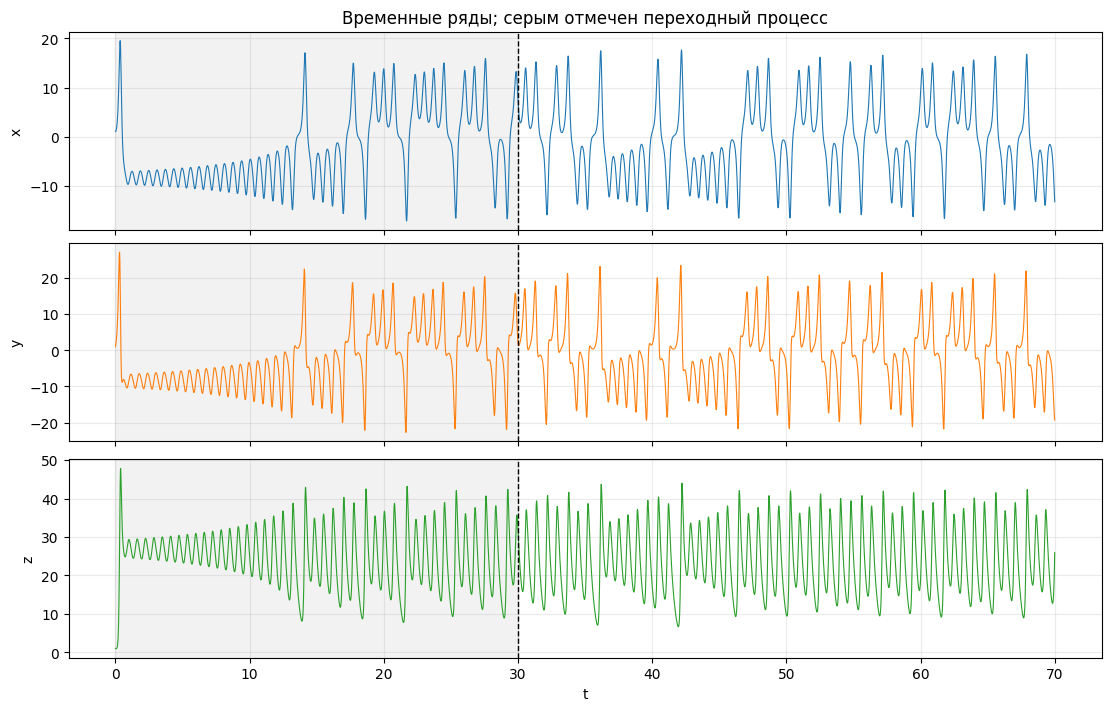

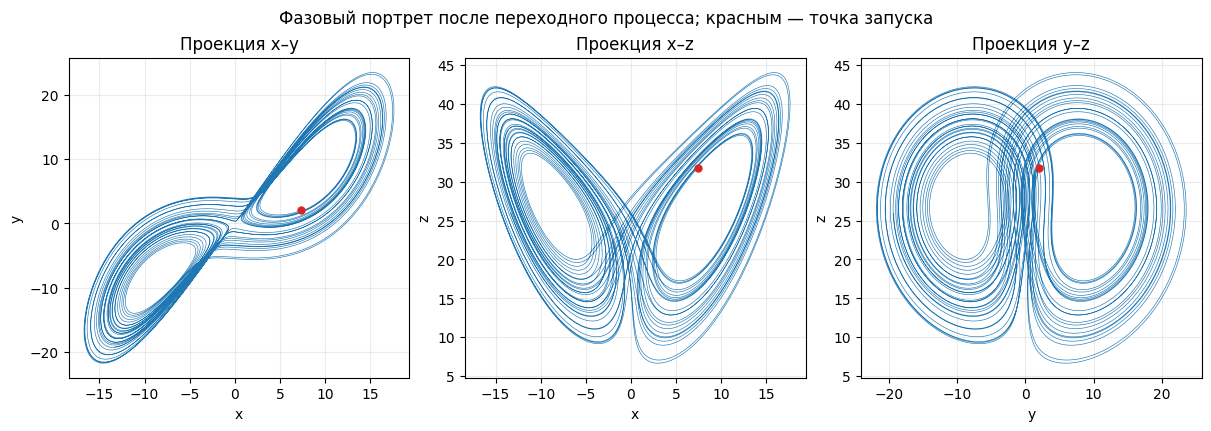

In [10]:
time_full = np.concatenate((time_warmup, t_transient + time[1:]))
state_full = np.vstack((warmup, base_fine[1:]))

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for i, (ax, name, color) in enumerate(zip(
        axes, ["x", "y", "z"], ["tab:blue", "tab:orange", "tab:green"])):
    ax.plot(time_full, state_full[:, i], color=color, lw=0.8)
    ax.axvspan(0.0, t_transient, color="gray", alpha=0.1)
    ax.axvline(t_transient, color="black", ls="--", lw=1)
    ax.set_ylabel(name)
axes[0].set_title("Временные ряды; серым отмечен переходный процесс")
axes[-1].set_xlabel("t")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), constrained_layout=True)
for ax, (i, j), (name_i, name_j) in zip(
        axes, [(0, 1), (0, 2), (1, 2)], [("x", "y"), ("x", "z"), ("y", "z")]):
    ax.plot(base_fine[:, i], base_fine[:, j], lw=0.45, color="tab:blue")
    ax.scatter(start[i], start[j], color="tab:red", s=25, zorder=4)
    ax.set_xlabel(name_i)
    ax.set_ylabel(name_j)
    ax.set_title(f"Проекция {name_i}–{name_j}")
fig.suptitle("Фазовый портрет после переходного процесса; красным — точка запуска")
plt.show()


## 3. Расстояние между траекториями и проверка точности

Начальные условия двух решений различаются только по $x$ на $\delta_0=10^{-6}$.
Расстояние вычисляется в евклидовой норме:

$$
d(\tau)=\|\mathbf u_{pert}(\tau)-\mathbf u_{base}(\tau)\|_2,
\qquad \mathbf u=(x,y,z).
$$

Этот расчёт повторяется при более строгих допусках и меньшем максимальном шаге.
Дополнительно вычисляется

$$
d_{num}(\tau)=\|\mathbf u_{base,basic}(\tau)-\mathbf u_{base,fine}(\tau)\|_2.
$$

У двух решений в $d_{num}$ начальные условия одинаковы: отличается только точность интегрирования.
Это расхождение между расчётами, а не известная ошибка относительно точного решения.
Перенормировка возмущения не выполняется.

In [11]:
d_basic = np.linalg.norm(pair_basic - base_basic, axis=1)
d_fine = np.linalg.norm(pair_fine - base_fine, axis=1)
d_num = np.linalg.norm(base_basic - base_fine, axis=1)

print(f"{'τ':>5} {'d: основной':>17} {'d: уточнённый':>17} {'d_num':>17}")
for tau in [0, 5, 10, 15, 20, 30, 40]:
    index = np.argmin(np.abs(time - tau))
    print(f"{time[index]:5.1f} {d_basic[index]:17.6e} "
          f"{d_fine[index]:17.6e} {d_num[index]:17.6e}")

early = (time >= 2.0) & (time <= 16.0)
print()
print("На участке 2 ≤ τ ≤ 16:")
print("max относительное различие двух кривых d =",
      f"{np.max(np.abs(d_basic[early] - d_fine[early])/d_fine[early]):.3e}")
print("max d_num / d_уточнённый =",
      f"{np.max(d_num[early]/d_fine[early]):.3e}")


    τ       d: основной     d: уточнённый             d_num
  0.0      1.000000e-06      1.000000e-06      0.000000e+00
  5.0      2.256481e-05      2.256481e-05      1.500917e-08
 10.0      1.020985e-03      1.020985e-03      6.454765e-07
 15.0      6.059330e-02      6.059231e-02      3.778743e-05
 20.0      2.149949e+01      2.151154e+01      1.868156e-02
 30.0      1.922674e+01      2.126167e+01      1.320458e+01
 40.0      1.370572e+01      5.062969e+01      2.449409e+01

На участке 2 ≤ τ ≤ 16:
max относительное различие двух кривых d = 2.449e-05
max d_num / d_уточнённый = 8.895e-04


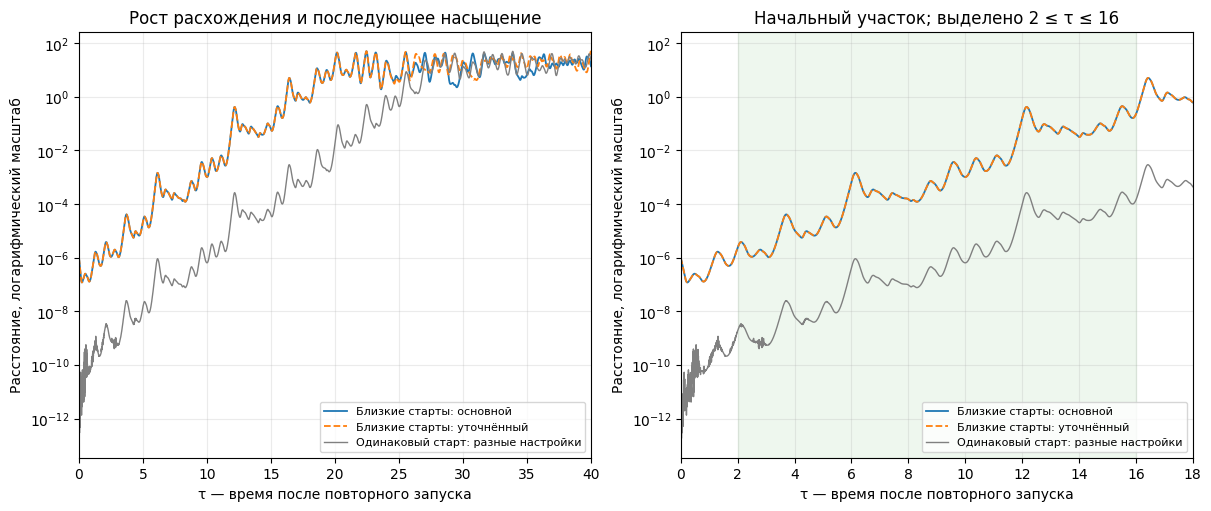

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax in axes:
    ax.semilogy(time, d_basic, color="tab:blue", lw=1.3, label="Близкие старты: основной")
    ax.semilogy(time, d_fine, color="tab:orange", ls="--", lw=1.3,
                label="Близкие старты: уточнённый")
    # При τ=0 d_num=0; нулевые значения в логарифмическом масштабе не рисуются.
    positive = d_num > 0.0
    ax.semilogy(time[positive], d_num[positive], color="gray", lw=1,
                label="Одинаковый старт: разные настройки")
    ax.set_xlabel("τ — время после повторного запуска")
    ax.set_ylabel("Расстояние, логарифмический масштаб")
    ax.legend(fontsize=8, loc="lower right")

axes[0].set_xlim(0.0, 40.0)
axes[0].set_title("Рост расхождения и последующее насыщение")
axes[1].set_xlim(0.0, 18.0)
axes[1].axvspan(2.0, 16.0, color="tab:green", alpha=0.08)
axes[1].set_title("Начальный участок; выделено 2 ≤ τ ≤ 16")
plt.show()


## 4. Ответ на вопрос и выводы

На участке примерно $2\le\tau\le16$ расстояние в среднем растёт экспоненциально:
на графике с логарифмической вертикальной осью его общий ход близок к восходящей прямой.
Рост не монотонный: чередуются локальные растяжения и сокращения расстояния.
Основная и уточнённая кривые на этом участке практически совпадают,
а расхождение решений с одинаковым стартом существенно меньше.
Поэтому здесь наблюдаемое разделение связано прежде всего с начальным возмущением.

Когда расстояние достигает масштаба аттрактора, примерно после $\tau\approx20$,
экспоненциальный рост сменяется колебаниями расстояния порядка десятков.
Оба решения движутся в ограниченной области фазового пространства,
поэтому расстояние между ними не может увеличиваться неограниченно.
При таком разделении приближение динамики разности линейными уравнениями уже неприменимо.

На больших временах расходятся и решения из одинаковой начальной точки
при разных допусках: малые численные ошибки также усиливаются.
Поэтому отдельные поздние пики расстояния нельзя считать воспроизводимыми
только на основании одного расчёта. Проверка точности подтверждает ранний рост
и картину насыщения, но не точное совпадение поздних траекторий.